In [1]:
# ── Installation (une seule fois dans Colab) ──────────────────────────────────
!pip install gymnasium[box2d] torch matplotlib --quiet

import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal   # distribution gaussienne pour actions continues
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# ── Reproductibilité ──────────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('✅ Imports OK')
print(f'   PyTorch  : {torch.__version__}')
print(f'   Gym      : {gym.__version__}')
print(f'   Device   : {"GPU" if torch.cuda.is_available() else "CPU"}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 79.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.3 MB/s eta 0:00:00
✅ Imports OK
   PyTorch  : 2.10.0+cu128
   Gym      : 1.3.0
   Device   : GPU


In [2]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=256):
        super().__init__()

        # ── Tronc commun (features partagées) ────────────────────────────────
        self.shared = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),          # Tanh est stable pour le RL (valeurs bornées)
            nn.Linear(hidden, hidden),
            nn.Tanh(),
        )

        # ── Tête Actor : prédit la moyenne μ des actions ──────────────────────
        self.actor_mean = nn.Linear(hidden, act_dim)

        # ── Log-écart type appris (indépendant de l'état, optimisable) ───────
        # On apprend log(σ) pour garantir σ > 0 partout
        self.log_std = nn.Parameter(torch.zeros(act_dim))

        # ── Tête Critic : prédit V(s) ─────────────────────────────────────────
        self.critic = nn.Linear(hidden, 1)

        # Initialisation orthogonale → gradients stables au départ
        self._init_weights()

    def _init_weights(self):
        for layer in self.shared:
            if isinstance(layer, nn.Linear):
                nn.init.orthogonal_(layer.weight, gain=np.sqrt(2))
                nn.init.zeros_(layer.bias)
        nn.init.orthogonal_(self.actor_mean.weight, gain=0.01)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)

    def forward(self, obs):
        """Retourne la distribution des actions ET la valeur d'état."""
        features = self.shared(obs)
        mean     = self.actor_mean(features)
        std      = self.log_std.exp().expand_as(mean)   # σ = e^(log σ)
        dist     = Normal(mean, std)                     # distribution gaussienne
        value    = self.critic(features)
        return dist, value

    def get_action(self, obs):
        """Échantillonne une action et retourne log π(a|s) + V(s)."""
        dist, value = self.forward(obs)
        action      = dist.sample()
        log_prob    = dist.log_prob(action).sum(-1)   # somme sur les dims d'action
        return action, log_prob, value.squeeze(-1)

    def evaluate(self, obs, actions):
        """Réévalue des actions passées (nécessaire pour le ratio PPO)."""
        dist, value = self.forward(obs)
        log_prob    = dist.log_prob(actions).sum(-1)
        entropy     = dist.entropy().sum(-1)          # entropie → encourage l'exploration
        return log_prob, value.squeeze(-1), entropy


# ── Test rapide du réseau ─────────────────────────────────────────────────────
env_test = gym.make('LunarLanderContinuous-v3')
net_test = ActorCritic(
    obs_dim=env_test.observation_space.shape[0],
    act_dim=env_test.action_space.shape[0]
).to(DEVICE)
env_test.close()

print('✅ ActorCritic créé')
print(f'   Paramètres : {sum(p.numel() for p in net_test.parameters()):,}')

✅ ActorCritic créé
   Paramètres : 68,869


In [3]:
class RolloutBuffer:
    def __init__(self):
        self.reset()

    def reset(self):
        self.obs, self.actions = [], []
        self.log_probs, self.rewards = [], []
        self.dones, self.values = [], []

    def store(self, obs, action, log_prob, reward, done, value):
        self.obs.append(obs)
        self.actions.append(action)
        self.log_probs.append(log_prob)
        self.rewards.append(reward)
        self.dones.append(done)
        self.values.append(value)

    def compute_advantages(self, last_value, gamma=0.99, lam=0.95):
        """
        Calcule les avantages GAE et les retours cibles pour le Critic.
        Parcours inversé (de la fin vers le début) pour le calcul récursif.
        """
        rewards    = np.array(self.rewards)
        dones      = np.array(self.dones)
        values     = np.array([v.item() for v in self.values])

        advantages = np.zeros_like(rewards)
        gae        = 0.0

        for t in reversed(range(len(rewards))):
            next_val  = last_value if t == len(rewards) - 1 else values[t + 1]
            next_done = 0 if t == len(rewards) - 1 else dones[t + 1]

            # δ_t = r_t + γ·V(s_{t+1})·(1-done) - V(s_t)
            delta = rewards[t] + gamma * next_val * (1 - next_done) - values[t]

            # A_t = δ_t + γλ·A_{t+1}
            gae   = delta + gamma * lam * (1 - next_done) * gae
            advantages[t] = gae

        # Retour cible pour entraîner le Critic
        returns = advantages + values

        # Normalisation → stabilité numérique
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        return advantages, returns

    def get_tensors(self):
        obs      = torch.FloatTensor(np.array(self.obs)).to(DEVICE)
        actions  = torch.FloatTensor(np.array(self.actions)).to(DEVICE)
        log_prob = torch.FloatTensor(
            np.array([lp.item() for lp in self.log_probs])
        ).to(DEVICE)
        return obs, actions, log_prob


print('✅ RolloutBuffer défini')

✅ RolloutBuffer défini


In [4]:
class PPOAgent:
    def __init__(
        self,
        obs_dim, act_dim,
        lr=3e-4,          # learning rate Adam
        gamma=0.99,       # discount factor
        lam=0.95,         # GAE lambda
        clip_eps=0.2,     # ε du clipping
        k_epochs=10,      # nb de passes d'optimisation par batch
        batch_size=64,    # mini-batch size
        vf_coef=0.5,      # c1 : poids de la loss Critic
        ent_coef=0.01,    # c2 : poids du bonus d'entropie
        max_grad_norm=0.5 # gradient clipping → évite les explosions
    ):
        self.gamma, self.lam         = gamma, lam
        self.clip_eps, self.k_epochs = clip_eps, k_epochs
        self.batch_size              = batch_size
        self.vf_coef, self.ent_coef  = vf_coef, ent_coef
        self.max_grad_norm           = max_grad_norm

        self.net    = ActorCritic(obs_dim, act_dim).to(DEVICE)
        self.optim  = optim.Adam(self.net.parameters(), lr=lr, eps=1e-5)
        self.buffer = RolloutBuffer()

    # ── Collecte d'une action (mode interaction) ──────────────────────────────
    @torch.no_grad()
    def select_action(self, obs):
        obs_t  = torch.FloatTensor(obs).unsqueeze(0).to(DEVICE)
        action, log_prob, value = self.net.get_action(obs_t)
        return (
            action.squeeze(0).cpu().numpy(),
            log_prob.squeeze(0),
            value.squeeze(0)
        )

    # ── Mise à jour PPO ───────────────────────────────────────────────────────
    def update(self, last_value):
        """Entraîne le réseau sur le buffer courant (K epochs, mini-batches)."""

        # 1. Calcul des avantages GAE
        advantages, returns = self.buffer.compute_advantages(
            last_value, self.gamma, self.lam
        )
        adv_t = torch.FloatTensor(advantages).to(DEVICE)
        ret_t = torch.FloatTensor(returns).to(DEVICE)

        # 2. Récupérer les données du buffer
        obs_t, act_t, old_log_t = self.buffer.get_tensors()
        T = obs_t.shape[0]

        total_loss_pg, total_loss_v, total_ent = [], [], []

        # 3. K passes d'optimisation sur le même batch
        for _ in range(self.k_epochs):
            indices = np.random.permutation(T)
            for start in range(0, T, self.batch_size):
                idx = indices[start : start + self.batch_size]

                # Réévaluer avec la politique ACTUELLE
                new_log, values, entropy = self.net.evaluate(obs_t[idx], act_t[idx])

                # ── Ratio π_new / π_old ───────────────────────────────────────
                ratio = torch.exp(new_log - old_log_t[idx])

                # ── L_CLIP ────────────────────────────────────────────────────
                surr1   = ratio * adv_t[idx]
                surr2   = torch.clamp(ratio, 1 - self.clip_eps, 1 + self.clip_eps) * adv_t[idx]
                loss_pg = -torch.min(surr1, surr2).mean()

                # ── L_VALUE (MSE Critic) ──────────────────────────────────────
                loss_v = nn.functional.mse_loss(values, ret_t[idx])

                # ── Loss totale ───────────────────────────────────────────────
                loss = loss_pg + self.vf_coef * loss_v - self.ent_coef * entropy.mean()

                self.optim.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), self.max_grad_norm)
                self.optim.step()

                total_loss_pg.append(loss_pg.item())
                total_loss_v.append(loss_v.item())
                total_ent.append(entropy.mean().item())

        # Buffer effacé après chaque update (on-policy !)
        self.buffer.reset()

        return (
            np.mean(total_loss_pg),
            np.mean(total_loss_v),
            np.mean(total_ent)
        )


print('✅ PPOAgent défini')

✅ PPOAgent défini


In [5]:
def train_ppo(
    env_id        = 'LunarLanderContinuous-v3',
    total_steps   = 2_000_000,  # budget total d'interactions
    n_steps       = 2048,       # steps collectés avant chaque update
    # ── hyperparamètres PPO ──
    lr            = 3e-4,
    gamma         = 0.99,
    lam           = 0.95,
    clip_eps      = 0.2,
    k_epochs      = 10,
    batch_size    = 64,
    vf_coef       = 0.5,
    ent_coef      = 0.005,
    # ── logging ──
    log_interval  = 10,         # afficher toutes les X updates
    target_reward = 200,        # seuil de convergence
):
    env     = gym.make(env_id)
    obs_dim = env.observation_space.shape[0]   # 8
    act_dim = env.action_space.shape[0]        # 2

    agent   = PPOAgent(obs_dim, act_dim, lr, gamma, lam, clip_eps,
                       k_epochs, batch_size, vf_coef, ent_coef)

    reward_history  = []
    episode_rewards = deque(maxlen=100)
    ep_reward       = 0.0
    steps_done      = 0
    update_count    = 0

    obs, _ = env.reset(seed=SEED)

    print(f'🚀 Démarrage PPO sur {env_id}')
    print(f'   obs_dim={obs_dim} | act_dim={act_dim} | budget={total_steps:,} steps\n')

    while steps_done < total_steps:

        # ── PHASE 1 : Collecte de n_steps transitions ─────────────────────────
        for _ in range(n_steps):
            action, log_prob, value = agent.select_action(obs)

            # Clipper dans l'espace valide de l'environnement
            clipped_action = np.clip(action,
                                     env.action_space.low,
                                     env.action_space.high)

            next_obs, reward, terminated, truncated, _ = env.step(clipped_action)
            done = terminated or truncated

            agent.buffer.store(obs, action, log_prob, reward, float(done), value)

            obs        = next_obs
            ep_reward += reward
            steps_done += 1

            if done:
                episode_rewards.append(ep_reward)
                ep_reward = 0.0
                obs, _    = env.reset()

        # ── PHASE 2 : Bootstrap de la valeur du dernier état ──────────────────
        with torch.no_grad():
            obs_t     = torch.FloatTensor(obs).unsqueeze(0).to(DEVICE)
            _, last_v = agent.net(obs_t)
            last_val  = last_v.item()

        # ── PHASE 3 : Mise à jour PPO (K epochs) ──────────────────────────────
        loss_pg, loss_v, entropy = agent.update(last_val)
        update_count += 1

        # ── Logging ───────────────────────────────────────────────────────────
        if len(episode_rewards) > 0:
            mean_r = np.mean(episode_rewards)
            reward_history.append(mean_r)

            if update_count % log_interval == 0:
                print(f'  Update {update_count:4d} | Steps {steps_done:7,} '
                      f'| Reward moy: {mean_r:7.1f} '
                      f'| Loss PG: {loss_pg:.4f} '
                      f'| Loss V: {loss_v:.4f} '
                      f'| Entropy: {entropy:.4f}')

            # ── Critère d'arrêt anticipé ──────────────────────────────────────
            if mean_r >= target_reward and len(episode_rewards) == 100:
                print(f'\n🎉 CONVERGENCE à l\'update {update_count} '
                      f'({steps_done:,} steps) — Reward moyen : {mean_r:.1f}')
                break

    env.close()
    return agent, reward_history


# ── Lancement ─────────────────────────────────────────────────────────────────
agent, ppo_rewards = train_ppo()

🚀 Démarrage PPO sur LunarLanderContinuous-v3
   obs_dim=8 | act_dim=2 | budget=2,000,000 steps

  Update   10 | Steps  20,480 | Reward moy:  -235.1 | Loss PG: -0.0022 | Loss V: 486.1413 | Entropy: 2.9023
  Update   20 | Steps  40,960 | Reward moy:   -71.7 | Loss PG: -0.0107 | Loss V: 70.3630 | Entropy: 2.7777
  Update   30 | Steps  61,440 | Reward moy:   -23.7 | Loss PG: -0.0046 | Loss V: 19.7522 | Entropy: 2.5656
  Update   40 | Steps  81,920 | Reward moy:    22.5 | Loss PG: -0.0007 | Loss V: 27.4335 | Entropy: 2.4545
  Update   50 | Steps 102,400 | Reward moy:    64.7 | Loss PG: -0.0018 | Loss V: 5.5852 | Entropy: 2.3895
  Update   60 | Steps 122,880 | Reward moy:    76.9 | Loss PG: -0.0016 | Loss V: 6.3303 | Entropy: 2.2984
  Update   70 | Steps 143,360 | Reward moy:    87.2 | Loss PG: 0.0020 | Loss V: 8.8915 | Entropy: 2.1032
  Update   80 | Steps 163,840 | Reward moy:   100.8 | Loss PG: -0.0041 | Loss V: 8.3153 | Entropy: 2.0100
  Update   90 | Steps 184,320 | Reward moy:    88.8 

## 📊 Cellule 6 — Visualisation des résultats

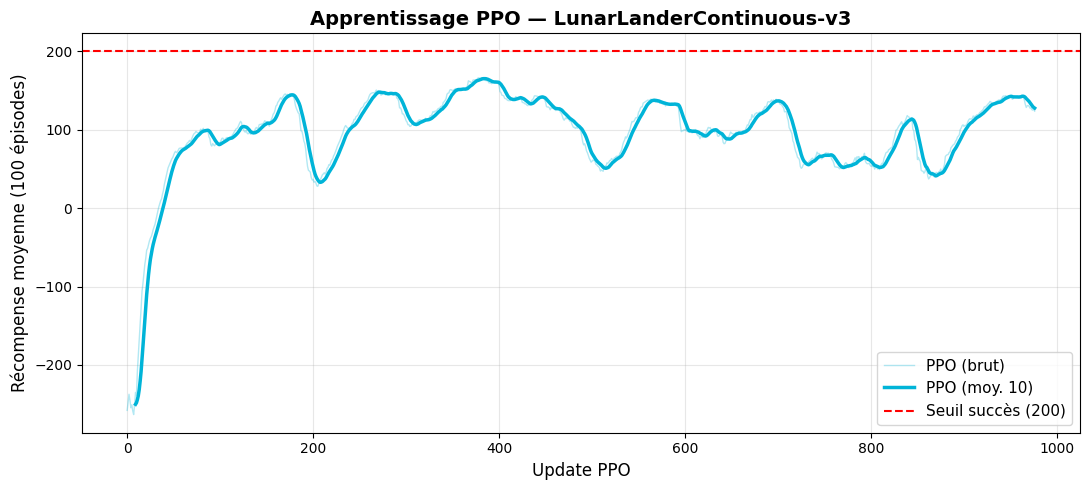

In [6]:
def plot_rewards(rewards, label='PPO', color='#00B4D8', window=10):
    plt.figure(figsize=(11, 5))
    plt.plot(rewards, alpha=0.3, color=color, linewidth=1, label=f'{label} (brut)')

    # Moyenne mobile pour lisser la courbe
    if len(rewards) >= window:
        smooth = np.convolve(rewards, np.ones(window)/window, mode='valid')
        plt.plot(range(window-1, len(rewards)), smooth,
                 color=color, linewidth=2.5, label=f'{label} (moy. {window})')

    plt.axhline(y=200, color='red', linestyle='--', linewidth=1.5, label='Seuil succès (200)')
    plt.xlabel('Update PPO', fontsize=12)
    plt.ylabel('Récompense moyenne (100 épisodes)', fontsize=12)
    plt.title('Apprentissage PPO — LunarLanderContinuous-v3', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_rewards(ppo_rewards)

In [7]:
import gymnasium as gym
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display
import numpy as np
import torch

def record_episode(agent, env_id='LunarLanderContinuous-v3', seed=0):
    env = gym.make(env_id, render_mode='rgb_array')
    obs, _ = env.reset(seed=seed)
    frames, total_reward, done = [], 0.0, False

    while not done:
        frames.append(env.render())
        obs_t = torch.FloatTensor(obs).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            dist, _ = agent.net.forward(obs_t)
            action = dist.mean.squeeze(0).cpu().numpy()
        action = np.clip(action, env.action_space.low, env.action_space.high)
        obs, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        done = terminated or truncated

    env.close()
    return frames, total_reward


def show_video(frames, reward):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.axis('off')
    fig.patch.set_facecolor('black')
    im = ax.imshow(frames[0])

    # ✅ Pas d'emoji (cause le warning), texte ASCII uniquement
    ax.set_title(f'[SUCCES] Objectif atteint !  Reward = {reward:.1f}',
                 color='lime', fontsize=13, fontweight='bold', pad=10)

    # ✅ Fonction propre au lieu du lambda — retourne bien une liste d'Artist
    def update(i):
        im.set_data(frames[i])
        return [im]

    anim = animation.FuncAnimation(
        fig, update,
        frames=len(frames),
        interval=40,
        blit=True
    )
    plt.tight_layout()
    plt.close()
    display(HTML(anim.to_html5_video()))


def find_and_show_success(agent, target=200, max_tries=20):
    print(f"Recherche d'un atterrissage avec reward >= {target}...\n")

    for seed in range(max_tries):
        frames, reward = record_episode(agent, seed=seed)
        status = "OK" if reward >= target else "--"
        print(f"  seed={seed:2d} | reward = {reward:7.1f}  [{status}]")

        if reward >= target:
            print(f"\nGeneration de la video (seed={seed})...")
            show_video(frames, reward)
            return

    print(f"\nAucun episode >= {target} en {max_tries} essais.")
    print("L'agent a besoin d'un entrainement plus long.")


# ── Lancer ────────────────────────────────────────────────────────────────────
find_and_show_success(agent, target=200, max_tries=20)

Recherche d'un atterrissage avec reward >= 200...

  seed= 0 | reward =   310.9  [OK]

Generation de la video (seed=0)...


In [8]:
class REINFORCEAgent:
    """Baseline REINFORCE — Monte Carlo Policy Gradient (Williams 1992)."""
    def __init__(self, obs_dim, act_dim, lr=3e-4, gamma=0.99):
        self.gamma = gamma
        hidden = 128

        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        ).to(DEVICE)
        self.mean_head = nn.Linear(hidden, act_dim).to(DEVICE)
        self.log_std   = nn.Parameter(torch.zeros(act_dim).to(DEVICE))

        params = (list(self.net.parameters()) +
                  list(self.mean_head.parameters()) + [self.log_std])
        self.optim = optim.Adam(params, lr=lr)

        self.log_probs_ep = []
        self.rewards_ep   = []

    def select_action(self, obs):
        obs_t    = torch.FloatTensor(obs).unsqueeze(0).to(DEVICE)
        features = self.net(obs_t)
        mean     = self.mean_head(features)
        dist     = Normal(mean, self.log_std.exp())
        action   = dist.sample()
        self.log_probs_ep.append(dist.log_prob(action).sum(-1))
        return action.squeeze(0).cpu().numpy()

    def store_reward(self, r):
        self.rewards_ep.append(r)

    def update(self):
        # Retours Monte-Carlo (pas de Critic, pas de GAE)
        G, returns = 0.0, []
        for r in reversed(self.rewards_ep):
            G = r + self.gamma * G
            returns.insert(0, G)

        returns = torch.FloatTensor(returns).to(DEVICE)
        returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        loss = -torch.stack(
            [lp * G for lp, G in zip(self.log_probs_ep, returns)]
        ).sum()

        self.optim.zero_grad()
        loss.backward()
        self.optim.step()

        self.log_probs_ep = []
        self.rewards_ep   = []
        return loss.item()


def train_reinforce(env_id='LunarLanderContinuous-v3', n_episodes=1500):
    env     = gym.make(env_id)
    obs_dim = env.observation_space.shape[0]
    act_dim = env.action_space.shape[0]
    agent   = REINFORCEAgent(obs_dim, act_dim)

    reward_history  = []
    episode_rewards = deque(maxlen=100)

    print(f'🚀 Démarrage REINFORCE sur {env_id}\n')

    for ep in range(1, n_episodes + 1):
        obs, _ = env.reset()
        ep_r   = 0.0
        done   = False

        while not done:
            action = agent.select_action(obs)
            action = np.clip(action, env.action_space.low, env.action_space.high)
            obs, r, term, trunc, _ = env.step(action)
            done   = term or trunc
            ep_r  += r
            agent.store_reward(r)

        agent.update()
        episode_rewards.append(ep_r)

        if ep % 50 == 0:
            mean_r = np.mean(episode_rewards)
            reward_history.append(mean_r)
            print(f'  Épisode {ep:5d} | Mean Reward (100 eps): {mean_r:7.1f}')

    env.close()
    return reward_history


reinforce_rewards = train_reinforce()

🚀 Démarrage REINFORCE sur LunarLanderContinuous-v3

  Épisode    50 | Mean Reward (100 eps):  -221.3
  Épisode   100 | Mean Reward (100 eps):  -171.7
  Épisode   150 | Mean Reward (100 eps):  -126.8
  Épisode   200 | Mean Reward (100 eps):  -108.4
  Épisode   250 | Mean Reward (100 eps):  -148.9
  Épisode   300 | Mean Reward (100 eps):  -157.2
  Épisode   350 | Mean Reward (100 eps):   -70.9
  Épisode   400 | Mean Reward (100 eps):   -47.8
  Épisode   450 | Mean Reward (100 eps):   -40.7
  Épisode   500 | Mean Reward (100 eps):    -5.9
  Épisode   550 | Mean Reward (100 eps):    16.8
  Épisode   600 | Mean Reward (100 eps):    31.8
  Épisode   650 | Mean Reward (100 eps):    10.4
  Épisode   700 | Mean Reward (100 eps):    26.5
  Épisode   750 | Mean Reward (100 eps):    62.6
  Épisode   800 | Mean Reward (100 eps):    53.9
  Épisode   850 | Mean Reward (100 eps):    77.2
  Épisode   900 | Mean Reward (100 eps):   105.3
  Épisode   950 | Mean Reward (100 eps):   113.5
  Épisode  1000 |

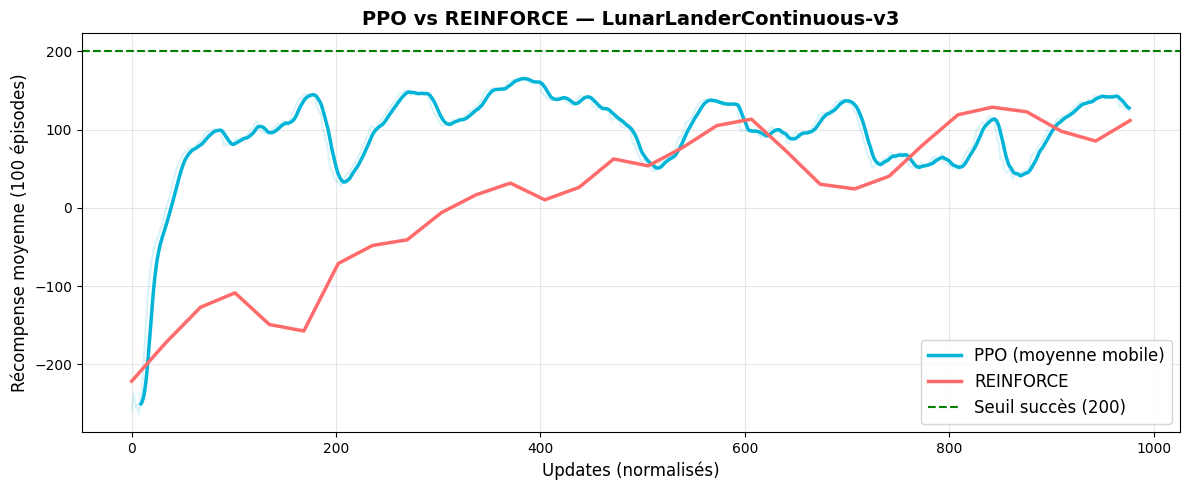

In [9]:
# ── Comparaison graphique PPO vs REINFORCE ────────────────────────────────────
plt.figure(figsize=(12, 5))

# PPO
if ppo_rewards:
    w = 10
    plt.plot(ppo_rewards, alpha=0.15, color='#00B4D8')
    if len(ppo_rewards) >= w:
        sm = np.convolve(ppo_rewards, np.ones(w)/w, mode='valid')
        plt.plot(range(w-1, len(ppo_rewards)), sm,
                 color='#00B4D8', lw=2.5, label='PPO (moyenne mobile)')

# REINFORCE
if reinforce_rewards:
    # Normaliser l'axe X pour comparer sur le même budget
    x_rf = np.linspace(0, len(ppo_rewards), len(reinforce_rewards))
    plt.plot(x_rf, reinforce_rewards, color='#FF6B6B', lw=2.5, label='REINFORCE')

plt.axhline(y=200, color='green', linestyle='--', lw=1.5, label='Seuil succès (200)')
plt.xlabel('Updates (normalisés)', fontsize=12)
plt.ylabel('Récompense moyenne (100 épisodes)', fontsize=12)
plt.title('PPO vs REINFORCE — LunarLanderContinuous-v3', fontsize=14, fontweight='bold')
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()